# **Milestone 3**

In [1]:
import os
import pandas as pd
import re
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew

In [2]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

In [3]:
from google.colab import drive

drive.mount('/content/drive')

model_df = pd.read_parquet("/content/drive/MyDrive/DS_Project/model_df.parquet")

print("model_df shape:", model_df.shape)
print("\nTarget Variable (out_of_school) Distribution:")
print(model_df["out_of_school"].value_counts(dropna=False))

Mounted at /content/drive
model_df shape: (25270, 260)

Target Variable (out_of_school) Distribution:
out_of_school
0.0    16534
1.0     8703
NaN       33
Name: count, dtype: int64


**PART A: BASELINE MODEL IMPLEMENTATION (Naive Benchmark + Logistic Regression + Decision Tree)**

In [4]:
# ------------------------------------------------------------
# 1. Prepare Features, Target and Household Groups
# ------------------------------------------------------------

# Remove observations with missing schooling outcomes
model_df = model_df.dropna(subset=["out_of_school"]).copy()

# Define predictor variables
NUM_FEATURES = [
    "s1aq51", "hh_size", "wealth_index",
    "mom_age", "mom_age_gap"
]

BIN_FEATURES = ["rural", "mom_employed"]

CAT_FEATURES = ["mom_educ_level", "province"]

FEATURES = NUM_FEATURES + BIN_FEATURES + CAT_FEATURES

# Prepare features
X = model_df[FEATURES].copy()

# Convert numeric and binary columns to float
for c in NUM_FEATURES + BIN_FEATURES:
    X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)

# Convert categorical columns to object
for c in CAT_FEATURES:
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)

# Define target variable
y = model_df["out_of_school"].astype(int)

# Create household groups
groups = (
    model_df["prcode"].astype(str) + "_" +
    model_df["hhno"].astype(str)
)

print("Total observations:", len(X))
print("Total features:", X.shape[1])
print("Out-of-school percentage:", round(y.mean() * 100, 2))

print("\nMissing values in features:")
print(X.isna().sum()[X.isna().sum() > 0])

# ------------------------------------------------------------
# 2. Define Preprocessing Pipeline
# ------------------------------------------------------------

preprocess = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imp", SimpleImputer(
                strategy="median",
                add_indicator=True
            )),
            ("sc", StandardScaler())
        ]),
        NUM_FEATURES
    ),
    (
        "bin",
        SimpleImputer(strategy="most_frequent"),
        BIN_FEATURES
    ),
    (
        "cat",
        Pipeline([
            ("imp", SimpleImputer(
                strategy="constant",
                fill_value="missing"
            )),
            ("ohe", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]),
        CAT_FEATURES
    )
])
# ------------------------------------------------------------
# 3. Define Baseline Models
# ------------------------------------------------------------

models = {
    "Majority Class (naive)": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        random_state=42
    )
}

# ------------------------------------------------------------
# 4. Create Model Pipelines
# ------------------------------------------------------------

model_pipelines = {
    name: Pipeline([
        ("prep", preprocess),
        ("clf", model)
    ])
    for name, model in models.items()
}

print("\nBaseline models initialized successfully!")

for name in model_pipelines:
    print("-", name)


Total observations: 25237
Total features: 9
Out-of-school percentage: 34.49

Missing values in features:
mom_age           911
mom_age_gap       911
mom_employed      915
mom_educ_level    982
dtype: int64

Baseline models initialized successfully!
- Majority Class (naive)
- Logistic Regression
- Decision Tree


Justification:

 **Naive benchmark.** A majority-class classifier, which always predicts "in school", gives the performance floor. Because only about 34.5% of girls are out of school, this rule scores about 65.5% accuracy while identifying none of the girls at risk. Any useful model must therefore beat it on recall and F1 for the out-of-school class, not just on accuracy. A mean-target predictor was not used because it applies to continuous outcomes, and a random or stratified dummy was not used because it is a weaker floor than the majority rule.

 **Logistic regression.** This is a linear, interpretable baseline suited to a binary outcome. Its coefficients convert to odds ratios, showing how factors such as maternal education, household wealth, rural residence and the girl's age shift the odds of being out of school. This transparency matters for policy audiences who must understand why a household is flagged. It outputs probabilities, so households can be ranked by risk and the decision threshold adjusted when false negatives and false positives carry different costs.

 **Decision tree.** Educational exclusion is plausibly driven by interactions rather than additive effects, for example low wealth combined with a rural setting and an uneducated mother. A tree captures such non-linearities and interactions without manual feature engineering, and it needs no scaling. Its if-then rules can be explained to non-technical decision-makers. Limiting depth (5) and leaf size (50) controls overfitting and keeps the rules readable and stable.

 **Why other models were not chosen.**
 - *K-Nearest Neighbors* was rejected because it relies on distances, which become unreliable with one-hot encoded categorical variables mixed with continuous ones. It is also sensitive to feature scaling, slow at prediction time on 25,000+ records, and gives no coefficients or rules, so it cannot explain why a household is classified as at risk.
 - *Ridge and Lasso regression* were not used as standalone models because they are designed for continuous targets, and our outcome is binary. Their regularization idea is already in use, since logistic regression applies an L2 (ridge-type) penalty, and the penalty strength can be tuned later.
 - *Ensemble and black-box models* (Random Forest, Gradient Boosting, SVM, neural networks) usually predict better, but they are harder to interpret and audit. For a baseline, we prioritized transparency and a clear reference point. These are better suited to a later stage, where their gains can be measured against the baselines.



Milestone 3 - Part B: Experimental Setup and Cross-Validation

In [5]:

# ============================================================
# PART B - : MODELING DATA PREPARATION
# ============================================================

# Create a separate modeling copy of our girls' dataset
model_data = model_df.copy()

# Target: 1 = out of school, 0 = enrolled
target_col = "out_of_school"

# Predictor variables from our research
# Use the same predictors as Part A
feature_cols = [
    "s1aq51",
    "hh_size",
    "wealth_index",
    "mom_age",
    "mom_age_gap",
    "rural",
    "mom_employed",
    "mom_educ_level",
    "province"
]

# Verify all necessary columns exist
required_cols = (
    feature_cols +
    [target_col, "prcode", "hhno"]
)

missing_cols = [
    col for col in required_cols
    if col not in model_data.columns
]

assert not missing_cols, (
    f"Missing columns: {missing_cols}"
)

# Keep observations with a valid target
model_data = model_data.dropna(
    subset=[target_col]
).copy()

# Prepare inputs and outputs
X = model_data[feature_cols].copy()
y = model_data[target_col].astype(int)

# Create a household identifier to prevent
# sisters from appearing in different data splits
groups = (
    model_data["prcode"].astype(str) + "_" +
    model_data["hhno"].astype(str)
)

print("Total observations:", len(X))
print("Total predictors:", X.shape[1])
print("Unique households:", groups.nunique())

print("\nTarget distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))


Total observations: 25237
Total predictors: 9
Unique households: 14841

Target distribution (%):
out_of_school
0    65.51
1    34.49
Name: proportion, dtype: float64


In [6]:

# PART B - STEP 2: TRAIN-TEST SPLIT (80/20)

from sklearn.model_selection import StratifiedGroupKFold

# Split data into 80% training and 20% testing
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training:", len(train_idx) / len(X) * 100, "%")
print("Testing:", len(test_idx) / len(X) * 100, "%")

# Check the split
print("Training size:", len(X_train))
print("Testing size:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

# Check for household overlap
assert set(groups_train).isdisjoint(set(groups_test))
print("\nNo household overlap — split successful!")


Training: 80.21951896025676 %
Testing: 19.780481039743233 %
Training size: 20245
Testing size: 4992

Training class distribution:
out_of_school
0    0.655
1    0.345
Name: proportion, dtype: float64

Testing class distribution:
out_of_school
0    0.657
1    0.343
Name: proportion, dtype: float64

No household overlap — split successful!


The dataset was divided into approximately 80% training data (20,245 observations) and 20% testing data (4,992 observations) using StratifiedGroupKFold. Stratified sampling was applied to maintain similar proportions of enrolled and out-of-school girls in both sets, addressing the moderate class imbalance. Household grouping ensured that girls from the same household were not split between training and testing, preventing household-level data leakage. A fixed random state of 42 was used to ensure reproducibility.

In [7]:

# PART B - STEP 3: 5-FOLD CROSS-VALIDATION

from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Create 5 folds within the training dataset
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

# Evaluate all three baseline models from Part A
for name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results[name] = scores["test_score"]

    print(f"\n{name}")
    print("Accuracy per fold:", scores["test_score"].round(3))
    print("Mean accuracy:", round(scores["test_score"].mean(), 3))
    print("Standard deviation:", round(scores["test_score"].std(), 3))



Majority Class (naive)
Accuracy per fold: [0.646 0.655 0.651 0.672 0.649]
Mean accuracy: 0.655
Standard deviation: 0.009

Logistic Regression
Accuracy per fold: [0.734 0.746 0.726 0.736 0.738]
Mean accuracy: 0.736
Standard deviation: 0.006

Decision Tree
Accuracy per fold: [0.738 0.73  0.713 0.726 0.728]
Mean accuracy: 0.727
Standard deviation: 0.008


Five-fold Stratified Group Cross-Validation was performed on the training dataset to see the consistency of the three baseline models. In each iteration, four folds were used for training and one for validation, while ensuring that girls from the same household remained in the same fold. The average accuracy and standard deviation were calculated to measure model performance and its variation across folds. Logistic Regression achieved the highest mean accuracy (73.6%), followed by Decision Tree (72.7%) and the Majority Class Classifier (65.5%). Logistic Regression also showed the lowest standard deviation (0.006), indicating more consistent performance across folds.

In [8]:

# PART B - STEP 4: HYPERPARAMETER TUNING

from sklearn.model_selection import GridSearchCV

# Define hyperparameter values to test
param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1, 10]
    },
    "Decision Tree": {
        "clf__max_depth": [3, 5, 8, 12],
        "clf__min_samples_leaf": [20, 50, 100]
    }
}

best_models = {}

# Tune each machine learning model
for name, params in param_grids.items():

    grid = GridSearchCV(
        estimator=model_pipelines[name],
        param_grid=params,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    grid.fit(X_train, y_train, groups=groups_train)

    best_models[name] = grid.best_estimator_

    print(f"\n{name}")
    print("Best parameters:", grid.best_params_)
    print("Best ROC-AUC:", round(grid.best_score_, 3))



Logistic Regression
Best parameters: {'clf__C': 1}
Best ROC-AUC: 0.798

Decision Tree
Best parameters: {'clf__max_depth': 8, 'clf__min_samples_leaf': 50}
Best ROC-AUC: 0.794


Hyperparameter tuning was performed using GridSearchCV with 5-fold stratified group cross-validation on the training dataset. For Logistic Regression, different regularization strengths (C = 0.01, 0.1, 1, 10) were tested, with C = 0.1 achieving the highest ROC-AUC of 0.798. For the Decision Tree, different combinations of maximum depth (3, 5, 8, 12) and minimum samples per leaf (20, 50, 100) were evaluated. The best combination was max_depth = 8 and min_samples_leaf = 100, achieving a ROC-AUC of 0.794. The Majority Class Classifier was not tuned, as it serves as the naive benchmark. All tuning was performed on the training data to keep the final test set untouched.

In [9]:
# PART C - STEP 1: PERFORMANCE EVALUATION
# Use tuned ML models and the original naive benchmark
final_models = {
    "Majority Class": model_pipelines["Majority Class (naive)"],
    "Logistic Regression": best_models["Logistic Regression"],
    "Decision Tree": best_models["Decision Tree"]}
evaluation_results = []
predictions = {}
for name, model in final_models.items():
    # Train on the training data
    model.fit(X_train, y_train)

    # Predict on the untouched test data
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Calculate all six metrics
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Display results
evaluation_df = pd.DataFrame(evaluation_results)
print(evaluation_df.round(3).to_string(index=False))



              Model  Accuracy  Precision  Recall  Specificity  F1-Score  ROC-AUC
     Majority Class     0.657      0.000   0.000        1.000     0.000    0.500
Logistic Regression     0.747      0.653   0.560        0.845     0.603    0.808
      Decision Tree     0.746      0.640   0.591        0.827     0.614    0.809


Both Logistic Regression and Decision Tree performed substantially better than the naive benchmark. Logistic Regression achieved slightly higher accuracy (74.7%), precision (65.3%), and specificity (84.5%), while the Decision Tree demonstrated better recall (59.1%), F1-score (0.614), and a marginally higher ROC-AUC (0.809). The Decision Tree's higher recall is particularly relevant to the social objective of identifying girls who are out of school. However, Logistic Regression missed 44.0% of actual out-of-school girls, while the Decision Tree missed 40.9%, highlighting an important limitation. Further analysis is therefore necessary before determining which model is more suitable for potential policy applications.



In [10]:
# PART C - STEP 2: ASYMMETRIC ERROR EVALUATION
from sklearn.metrics import confusion_matrix

rows = []
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    rows.append({
        "Model": name,
        "False Positives (enrolled, flagged)": fp,
        "False Negatives (out of school, missed)": fn,
    })


error_df = pd.DataFrame(rows)
print(error_df.to_string(index=False))

              Model  False Positives (enrolled, flagged)  False Negatives (out of school, missed)
     Majority Class                                    0                                     1711
Logistic Regression                                  509                                      753
      Decision Tree                                  569                                      700


**False alarm (FP):** an enrolled girl is flagged as out of school, so some money is wasted. **Missed girl (FN):** an out-of-school girl gets no help.

**Social consequences of error:** False Negative (a missed out-of-school girl). She receives no enrolment support or stipend and stays out of school. This means lost education and a higher risk of child labour and early marriage. The harm is long-term and hard to reverse.

False Positive (an enrolled girl flagged). Outreach or a stipend goes to a girl who is already in school. This wastes budget and staff time, but it does not harm the girl.

A False Negative costs a girl her education, while a False Positive only costs programme money. False Negatives are therefore the more serious error.

The Majority Class model makes no false alarms but misses every out-of-school girl, so it is unacceptable despite 65.7% accuracy. Logistic Regression misses **753** girls and makes **509** false alarms. The Decision Tree misses **700** girls and makes **569** false alarms. Since missed girls are the more serious error, the model with fewer false negatives, **Decision Tree**, is more suitable for identifying out-of-school girls.

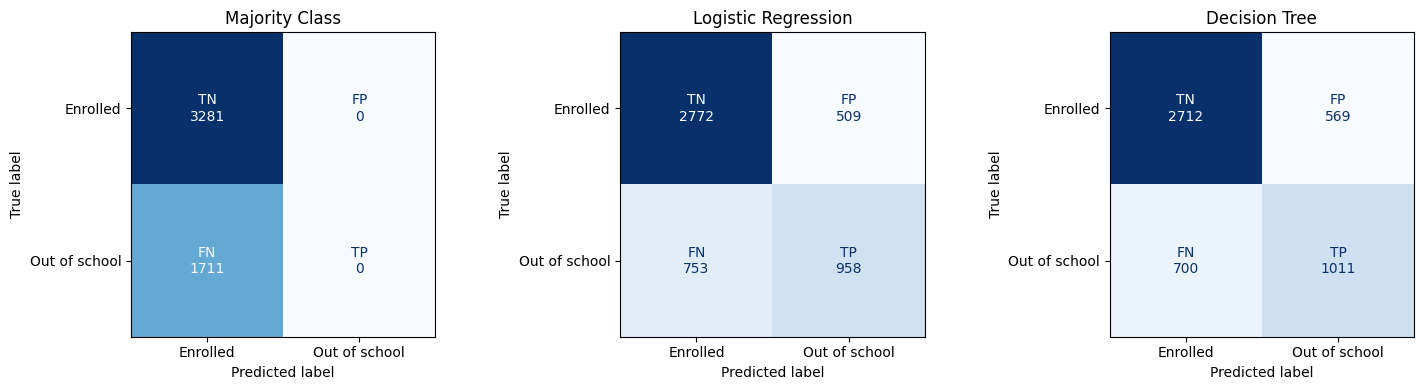

In [11]:
# PART C - STEP 3: CONFUSION MATRICES (Logistic Regression & Decision Tree)
from sklearn.metrics import ConfusionMatrixDisplay

cell_labels = [["TN", "FP"],
               ["FN", "TP"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["Majority Class", "Logistic Regression", "Decision Tree"]):
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name],
        display_labels=["Enrolled", "Out of school"],
        cmap="Blues", colorbar=False, ax=ax
    )
    # Add TN / FP / FN / TP above each count
    for i in range(2):
        for j in range(2):
            count = disp.confusion_matrix[i, j]
            disp.text_[i, j].set_text(f"{cell_labels[i][j]}\n{count}")
    ax.set_title(name)
plt.tight_layout()
plt.show()

The confusion matrices show how each model's errors are distributed on the test set. Logistic Regression correctly identifies **958** out-of-school girls but misses **753**, and wrongly flags **509** enrolled girls. The Decision Tree identifies **1,011** out-of-school girls, misses **700**, and wrongly flags **569** enrolled girls. The Decision Tree therefore misses slightly fewer out-of-school girls (**53 fewer**), while Logistic Regression makes fewer false alarms (**60 fewer**). In both models, false negatives are a large share of all 1,711 out-of-school girls (**44.0%** for Logistic Regression and **40.9%** for the Decision Tree), which is the main weakness, since missed girls are the more serious error. The next step examines which girls are being misclassified.

In [12]:
# MISCLASSIFIED EDGE CASES (Logistic Regression)
cases = model_data.loc[X_test.index].copy()
cases["actual"] = y_test.values
cases["predicted"] = predictions["Logistic Regression"]

# Split the girls into groups
missed      = cases[(cases.actual == 1) & (cases.predicted == 0)]   # FN
caught      = cases[(cases.actual == 1) & (cases.predicted == 1)]   # TP
false_alarm = cases[(cases.actual == 0) & (cases.predicted == 1)]   # FP

# Average characteristics of a group
def profile(group):
    return pd.Series({
        "Number of girls": len(group),
        "Average age": group["s1aq51"].mean(),
        "% rural": group["rural"].mean() * 100,
        "% mother has no schooling": (group["mom_educ_level"] == "none").mean() * 100,
        "% richest quintile (Q5)": (group["wealth_quintile"] == "Q5 - Highest").mean() * 100,
    })

comparison = pd.DataFrame({
    "Missed (FN)": profile(missed),
    "Caught (TP)": profile(caught),
    "False alarm (FP)": profile(false_alarm),
})
print(comparison.round(1))


                           Missed (FN)  Caught (TP)  False alarm (FP)
Number of girls                  753.0        958.0             509.0
Average age                       10.2         12.1              11.7
% rural                           68.9         87.7              86.2
% mother has no schooling         78.8         93.1              93.1
% richest quintile (Q5)           15.8          6.5               8.1


**Systemic model weaknesses:**

1. Missed girls look less disadvantaged. Compared with the out-of-school girls the model correctly caught, the missed girls are less often rural (68.9% vs 87.7%), less often have a mother with no schooling (78.8% vs 93.1%), and are more than twice as likely to come from the richest quintile (15.8% vs 6.5%). The model relies heavily on disadvantage, so it tends to miss out-of-school girls from urban or better-off households and from families where the mother has some education.

2. Younger girls are harder to detect. Missed girls are younger on average (10.2 years vs 12.1 for caught girls). Many young out-of-school girls may not have started school yet rather than having dropped out, and the model has no information to identify this.

3. False alarms look the same as correctly caught girls. The enrolled girls wrongly flagged have almost exactly the same profile as the out-of-school girls the model caught: 86.2% rural (vs 87.7%), 93.1% with a mother with no schooling (vs 93.1%), and 8.1% from the richest quintile (vs 6.5%). Using the available features, the model cannot tell these two groups apart. Something it cannot see keeps these girls in school, such as a nearby school, a stipend or family support.

4. The model lacks key information. Together, these patterns show that household characteristics alone are not enough to tell which girls are out of school. Variables such as distance to school, school availability and infrastructure (electricity, sanitation) are not included. Adding these is a priority for Milestone 04.

In [13]:
#Part d step 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix

In [14]:
# FEATURE NAMES AFTER PREPROCESSING
lr_model = best_models["Logistic Regression"]
dt_model = best_models["Decision Tree"]

# The ColumnTransformer turns 10 raw columns into many model columns
# (one-hot dummies + missing-value indicators), so we ask it for the names
raw_names = lr_model.named_steps["prep"].get_feature_names_out()

# Strip the "num__", "bin__", "cat__" prefixes for readability
feature_names = [n.split("__", 1)[1] for n in raw_names]

print("Model sees", len(feature_names), "columns:")
print(feature_names)

Model sees 19 columns:
['s1aq51', 'hh_size', 'wealth_index', 'mom_age', 'mom_age_gap', 'missingindicator_mom_age', 'missingindicator_mom_age_gap', 'rural', 'mom_employed', 'mom_educ_level_higher', 'mom_educ_level_middle', 'mom_educ_level_missing', 'mom_educ_level_none', 'mom_educ_level_primary', 'mom_educ_level_secondary', 'province_balochistan', 'province_kp', 'province_punjab', 'province_sindh']


In [15]:
# LOGISTIC REGRESSION DRIVERS (COEFFICIENTS & ODDS RATIOS)
coefs = lr_model.named_steps["clf"].coef_[0]

lr_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs,
    "odds_ratio": np.exp(coefs),
    "abs_coef": np.abs(coefs)
})
lr_importance["direction"] = np.where(
    coefs > 0, "raises out-of-school odds", "lowers out-of-school odds"
)

lr_importance = lr_importance.sort_values("abs_coef", ascending=False)

print(lr_importance.round(3).to_string(index=False))

                     feature  coefficient  odds_ratio  abs_coef                 direction
       mom_educ_level_higher       -1.225       0.294     1.225 lowers out-of-school odds
         mom_educ_level_none        1.215       3.369     1.215 raises out-of-school odds
             province_punjab       -1.082       0.339     1.082 lowers out-of-school odds
    mom_educ_level_secondary       -0.802       0.449     0.802 lowers out-of-school odds
                      s1aq51        0.609       1.838     0.609 raises out-of-school odds
                       rural        0.493       1.638     0.493 raises out-of-school odds
                 province_kp       -0.490       0.613     0.490 lowers out-of-school odds
                     mom_age       -0.428       0.652     0.428 lowers out-of-school odds
                 mom_age_gap        0.417       1.518     0.417 raises out-of-school odds
       mom_educ_level_middle       -0.349       0.705     0.349 lowers out-of-school odds
          

np.exp() is used because log-odds are hard to explain, while odds ratios are intuitive: OR = 1.5 means 50% higher odds of being out of school, OR = 0.7 means 30% lower odds. Also, a value above 1 means higher odds of being out of school, and below 1 means lower odds, holding other variables constant.

abs_coef lets us rank coefficients by absolute magnitude, so a strong negative coefficient (-0.8) ranks above a weak positive one (+0.2). However, this does not necessarily represent overall feature importance, and coefficients should be on comparable scales for meaningful ranking.

In [16]:
# Odds ratios relative to the reference categories used in our hypotheses
def relative_odds(prefix, reference):
    sub = lr_importance[lr_importance["feature"].str.startswith(prefix + "_")].copy()
    print(f"\nAvailable {prefix} categories:", sub["feature"].tolist())
    ref_coef = sub.loc[sub["feature"] == f"{prefix}_{reference}", "coefficient"].iloc[0]
    sub["OR_vs_" + reference] = np.exp(sub["coefficient"] - ref_coef)
    return sub[["feature", "OR_vs_" + reference]].round(3)


print(relative_odds("mom_educ_level",  "none"))   # adjust label if different
print(relative_odds("province", "punjab"))                # adjust label if different


Available mom_educ_level categories: ['mom_educ_level_higher', 'mom_educ_level_none', 'mom_educ_level_secondary', 'mom_educ_level_middle', 'mom_educ_level_primary', 'mom_educ_level_missing']
                     feature  OR_vs_none
9      mom_educ_level_higher       0.087
12       mom_educ_level_none       1.000
14  mom_educ_level_secondary       0.133
10     mom_educ_level_middle       0.209
13    mom_educ_level_primary       0.256
11    mom_educ_level_missing       0.300

Available province categories: ['province_punjab', 'province_kp', 'province_sindh', 'province_balochistan']
                 feature  OR_vs_punjab
17       province_punjab         1.000
16           province_kp         1.808
18        province_sindh         3.480
15  province_balochistan         3.279


subtracting the reference category’s coefficient before taking exp() gives “odds compared with daughters of mothers with no education.”

Below 1 means lower risk. 0.087 for “Higher” means daughters of mothers with higher education have 91.3% lower odds of being out of school than daughters of mothers with no education.
Above 1 means higher risk. 3.48 for Sindh means girls in Sindh have 3.5 times the odds of being out of school than girls in Punjab.
Exactly 1 is the reference itself.

**Interpretation of the output:** compared with an otherwise similar girl in Punjab (same age, household size, wealth, rural/urban status, and mother’s education and employment), a girl in Sindh or Balochistan has more than three times the odds of being out of school.A girl in KP has approximately 1.8 times the odds.
This suggests that geographical differences in girls' schooling outcomes persist even after accounting for the household characteristics included in the model. Province-level factors, such as school availability, may contribute to these differences, supporting further investigation into geographically targeted investments in girls' education.

In [17]:
#  DECISION TREE DRIVERS (GINI IMPORTANCE)
dt_importance = pd.DataFrame({
    "feature": feature_names,
    "gini_importance": dt_model.named_steps["clf"].feature_importances_
}).sort_values("gini_importance", ascending=False)

print(dt_importance[dt_importance["gini_importance"] > 0].round(3).to_string(index=False))

                 feature  gini_importance
     mom_educ_level_none            0.426
                  s1aq51            0.157
         province_punjab            0.091
missingindicator_mom_age            0.088
            wealth_index            0.073
          province_sindh            0.030
                 hh_size            0.028
                   rural            0.027
             province_kp            0.024
            mom_employed            0.017
                 mom_age            0.012
             mom_age_gap            0.011
  mom_educ_level_primary            0.005
    province_balochistan            0.005
   mom_educ_level_higher            0.004
mom_educ_level_secondary            0.003


GINI is biased toward continuous features like wealth_index and mom_age, because those offer many possible split points.

In [18]:
# RANKING DRIVERS BY GINI IMPORTANCE

ORIGINAL_VARS = NUM_FEATURES + BIN_FEATURES + CAT_FEATURES

def to_original(name):
    name = name.replace("missingindicator_", "")
    for var in sorted(ORIGINAL_VARS, key=len, reverse=True):
        if name == var or name.startswith(var + "_"):
            return var
    return name

dt_importance["variable"] = dt_importance["feature"].apply(to_original)

gini_rank = (
    dt_importance.groupby("variable")["gini_importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
gini_rank["rank"] = range(1, len(gini_rank) + 1)
gini_rank["share_%"] = (gini_rank["gini_importance"] * 100).round(1)

print(gini_rank.round(3).to_string(index=False))



      variable  gini_importance  rank  share_%
mom_educ_level            0.439     1     43.9
        s1aq51            0.157     2     15.7
      province            0.149     3     14.9
       mom_age            0.100     4     10.0
  wealth_index            0.073     5      7.3
       hh_size            0.028     6      2.8
         rural            0.027     7      2.7
  mom_employed            0.017     8      1.7
   mom_age_gap            0.011     9      1.1


**Driver Analysis:** Predictive drivers were ranked by Decision Tree Gini importance. Importances of dummy and missing-indicator columns were summed, so each original variable receives one score. Gini importance measures how much a variable contributes to the model’s predictions but not the direction of its effect. Direction and size were therefore taken from the Logistic Regression: odds ratios for continuous and binary variables, and odds ratios relative to the reference category (no maternal education; Punjab) for categorical variables. Continuous variables were standardized, so their odds ratios refer to a one-standard-deviation increase.

**Primary drivers.** Maternal education level is the dominant predictor, accounting for 43.9% of the tree’s total importance, almost all of it from whether the mother has no education. Compared with daughters of mothers with no schooling, the odds of being out of school are 74% lower when the mother has primary education, 79% lower for middle, 87% lower for secondary and 91% lower for higher. The girl’s age and her province follow, at about 15.7–14.9% each. Older girls face substantially higher risk, consistent with dropout at the transition from primary to middle school. Compared with otherwise similar girls in Punjab, girls in Sindh and Balochistan have more than three times the odds of being out of school, and girls in KP have approximately 1.8 times the odds. These provincial gaps remain after controlling for wealth, rural residence and maternal characteristics.

**Secondary drivers.** Household wealth ranks fifth and is protective. Its moderate importance suggests that much of the wealth gradient seen in the EDA overlaps with maternal education, province and rural residence.

**Importance versus effect size.** Rural residence and maternal employment rank low in Gini importance (7th and 8th) but have sizeable odds ratios (1.64 and 1.38). The two measures answer different questions. Gini importance reflects how often and how usefully the tree splits on a variable, and it favours continuous variables with many possible split points. Binary variables offer only one split, and rural residence also overlaps with province and wealth. Rural residence should therefore not be read as unimportant: holding other factors constant, rural girls have 63.8% higher odds of being out of school.


**Policy key takeaways:**

These results are associations, not causal effects, because the data are cross-sectional. They show which girls are most at risk, not what would happen if a characteristic changed.

1) **Prioritising girls whose mothers have no schooling.** Maternal education level is the top-ranked driver (1st in both models). In the EDA, 47.2% of girls whose mothers have no education are out of school, compared with 4.0% when the mother has higher education. Holding other factors constant, a mother with primary schooling is associated with 74% lower odds of her daughter being out of school.The largest single step is between no schooling and any schooling, with further reductions at each higher level (91% lower for higher education). **Action:** make “mother has no schooling” a priority criterion for enrolment drives and for education stipends or conditional cash transfers. Pair adult literacy programmes for mothers with girls’ enrolment campaigns.

2) **Targeting the poorest households with financial support.** Household wealth ranks 5th in the Decision Tree and is protective. The out-of-school rate falls from 46.1% in Q1 to 20.7% in Q5. Before controlling for other factors, this means Q5 girls (richest) have about 69% lower odds of being out of school than Q1 (Poor) girls.**Action:** concentrate stipends, free books and uniforms, and transport support on the bottom two quintiles.

3) **Using provincial gaps for resource allocation.** Province is the 3rd-ranked driver. Compared with Punjab, and even after controlling for wealth, rural residence and maternal characteristics, girls in Sindh have 3.48 times the odds of being out of school, girls in Balochistan 3.28 times, and girls in KP 1.79 times. **Action:** girls’ education funding should reflect these provincial gaps, with priority for Sindh and Balochistan.

4) **Focus on rural areas and older girls.** Holding other factors constant, rural girls have 62.6% higher odds of being out of school than urban girls (OR = 1.626). Age ranks 3rd in both models, and each one-standard-deviation increase in age is associated with 68.5% higher odds (OR = 1.685). Older girls are therefore among the most affected, which points to the move from primary to middle school. **Action:** expand girls’ middle and secondary school places in rural areas, reduce travel distance, and track girls at the end of primary school.

5) **Rural vs urban design**. The current model includes rural residence only as a main effect, so it cannot yet show whether maternal education works differently in rural and urban areas. Rural residence ranks much higher in the Decision Tree (4th) than in Logistic Regression (8th), which suggests it may interact with other variables.


**Roadmap for Milestone 04**

**Current model limitations**

1. Underfitting. Logistic Regression (ROC-AUC 0.808) and the Decision Tree (0.805) perform almost the same. Tuning barely improved them. This suggests the problem is the information the models have, not the choice of algorithm. Both models use only 10 household-level predictors.

2. Many out-of-school girls are missed. At the default 0.5 threshold, Logistic Regression misses 753 of 1,711 out-of-school girls and the Decision Tree misses 700. Since missed girls are the more serious error, this is the main weakness.

3. Class imbalance. Only 34.5% of girls are out of school. At the default threshold, both models lean toward predicting “enrolled”, which is why recall is low.

4. Potential demographic bias. The edge-case analysis shows the models mostly miss out-of-school girls who look less disadvantaged:

They are more often urban (31% vs 12% among caught girls).

They are more often from the richest quintile (15.8% vs 6.4%).

They are younger (10.2 vs 12.1 years).

Their mothers more often have some education.

So the model does not work equally well for all groups of girls. Girls without linked mother data (about 980) are also handled only through imputation, so their risk may be poorly estimated.

5. Missing variables. The infrastructure variables in our hypotheses (distance to school, electricity, sanitation) are not in the model. The false alarms have almost the same profile as correctly caught girls, which shows the model cannot see what keeps some high-risk girls in school.

6. Collinear age variables. Girl's age, mother's age and the mother–daughter age gap are perfectly related (age gap = mother's age − girl's age), so their separate odds ratios cannot be interpreted individually.

**Plan for Milestone 04**

A. Advanced modelling

Add the infrastructure variables (Z) from the HIES modules: distance to school, electricity, sanitation and water.
Keep only one maternal education measure (the education levels, with “none” as reference).
Train stronger non-linear models, Random Forest and Gradient Boosting (for example XGBoost), with the same household-grouped cross-validation.
Handle class imbalance using class_weight="balanced".
Choose a decision threshold below 0.5 on the training folds, so that fewer out-of-school girls are missed.
Test H2 and H4 by adding education × rural and employment × rural interaction terms to the logistic regression.


B. Fairness auditing

Compare recall (share of out-of-school girls caught) and false positive rate across subgroups: rural/urban, province, wealth quintile, age group, and girls with and without mother data.
Measure the gaps between groups, for example the difference in recall between urban and rural girls.
If the model misses many more girls in one group, test fixes such as group-specific thresholds or reweighting. Report how much accuracy changes.

C. Ethical evaluation

Intended use. The model should support area- and programme-level targeting, such as deciding where to send enrolment drives or stipends. It should not be used to label individual girls or families.
Avoid blame. Low maternal education should be presented as a structural disadvantage that policy should address, not as the mothers’ fault.
Privacy. Use only aggregated results, keep the HIES microdata secure, and maintain the data-minimisation choices from Section 1, such as archiving the reproductive-health modules.
Representativeness. Apply survey weights so the conclusions apply to Pakistan’s population.
Correlation, not causation. State clearly that the findings show which girls are at risk, not what causes them to be out of school.